# 🏥 RadiSense AI - Exploration des Données

**Projet :** Plateforme de diagnostic radiologique assisté par IA  
**Dataset :** ChestX-ray14 (NIH Clinical Center)  
**Auteur :** Syrine Trabelsi  
**Date :** Février 2026

---

## 📋 Objectifs

- Détection automatique de **14 pathologies pulmonaires**
- **Accuracy cible :** > 94%
- **AUC-ROC cible :** > 0.85
- **Temps d'analyse :** < 5 secondes

---

## 📦 Imports et Configuration

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import glob
import random
from collections import Counter

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 6)

print("✅ Imports OK!")
print(f"📊 NumPy : {np.__version__}")
print(f"📊 Pandas : {pd.__version__}")

✅ Imports OK!
📊 NumPy : 1.26.2
📊 Pandas : 2.1.3


## 📊 Informations sur le Dataset

### ChestX-ray14 (NIH Clinical Center)

- **Nombre d'images :** 112,120 radiographies thoraciques
- **Résolution :** 1024×1024 pixels
- **Format :** PNG (niveaux de gris, 8-bit)
- **Taille totale :** ~42 GB
- **Source :** [NIH Clinical Center](https://nihcc.app.box.com/v/ChestXray-NIHCC)

## 📂 Vérification de la Structure

In [2]:
# Vérifier la structure
data_path = "../data/raw"

if os.path.exists(data_path):
    print("✅ Dossier data/raw existe")
    
    files = os.listdir(data_path)
    print(f"\n📁 Contenu de data/raw ({len(files)} éléments) :\n")
    
    for item in sorted(files)[:15]:  # Afficher les 15 premiers
        item_path = os.path.join(data_path, item)
        if os.path.isdir(item_path):
            print(f"  📁 {item}/")
        else:
            size = os.path.getsize(item_path) / 1024 / 1024  # MB
            print(f"  📄 {item} ({size:.1f} MB)")
else:
    print("❌ Dossier data/raw n'existe pas !")

✅ Dossier data/raw existe

📁 Contenu de data/raw (20 éléments) :

  📄 ARXIV_V5_CHESTXRAY.pdf (8.5 MB)
  📄 BBox_List_2017.csv (0.1 MB)
  📄 Data_Entry_2017.csv (7.5 MB)
  📄 FAQ_CHESTXRAY.pdf (0.1 MB)
  📄 LOG_CHESTXRAY.pdf (0.0 MB)
  📄 README_CHESTXRAY.pdf (0.8 MB)
  📁 images_001/
  📁 images_002/
  📁 images_003/
  📁 images_004/
  📁 images_005/
  📁 images_006/
  📁 images_007/
  📁 images_008/
  📁 images_009/


In [4]:
# Compter les images (dans le sous-dossier images/)
image_folders = sorted(glob.glob("../data/raw/images_*"))
print(f"📁 Dossiers d'images trouvés : {len(image_folders)}\n")

total_images = 0
for folder in image_folders:
    # Chercher dans le sous-dossier images/
    images = glob.glob(f"{folder}/images/*.png")
    total_images += len(images)
    folder_name = folder.split('\\')[-1]  # Windows
    print(f"  {folder_name:15s} : {len(images):,} images")

print(f"\n✅ TOTAL : {total_images:,} images")

📁 Dossiers d'images trouvés : 12

  images_001      : 4,999 images
  images_002      : 10,000 images
  images_003      : 10,000 images
  images_004      : 10,000 images
  images_005      : 10,000 images
  images_006      : 10,000 images
  images_007      : 10,000 images
  images_008      : 10,000 images
  images_009      : 10,000 images
  images_010      : 10,000 images
  images_011      : 10,000 images
  images_012      : 7,121 images

✅ TOTAL : 112,120 images


## 📊 Analyse du fichier CSV (Labels)

In [5]:
# Charger le CSV des labels
csv_path = "../data/raw/Data_Entry_2017.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("✅ CSV chargé avec succès !")
    print(f"📊 Nombre de lignes : {len(df):,}")
    print(f"📋 Nombre de colonnes : {len(df.columns)}")
    print(f"\n🔍 Colonnes : {list(df.columns)}")
    print(f"\n📄 Aperçu des 5 premières lignes :")
    display(df.head())
else:
    print("❌ Fichier CSV non trouvé !")

✅ CSV chargé avec succès !
📊 Nombre de lignes : 112,120
📋 Nombre de colonnes : 12

🔍 Colonnes : ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']

📄 Aperçu des 5 premières lignes :


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


## 🏥 Distribution des Pathologies

In [6]:
# Compter les pathologies
all_findings = []
for finding in df['Finding Labels']:
    all_findings.extend(finding.split('|'))

finding_counts = Counter(all_findings)

# Afficher
print("📊 Distribution des pathologies :\n")
for finding, count in finding_counts.most_common():
    percentage = (count / len(df)) * 100
    print(f"  {finding:25s} : {count:6,} ({percentage:5.2f}%)")

📊 Distribution des pathologies :

  No Finding                : 60,361 (53.84%)
  Infiltration              : 19,894 (17.74%)
  Effusion                  : 13,317 (11.88%)
  Atelectasis               : 11,559 (10.31%)
  Nodule                    :  6,331 ( 5.65%)
  Mass                      :  5,782 ( 5.16%)
  Pneumothorax              :  5,302 ( 4.73%)
  Consolidation             :  4,667 ( 4.16%)
  Pleural_Thickening        :  3,385 ( 3.02%)
  Cardiomegaly              :  2,776 ( 2.48%)
  Emphysema                 :  2,516 ( 2.24%)
  Edema                     :  2,303 ( 2.05%)
  Fibrosis                  :  1,686 ( 1.50%)
  Pneumonia                 :  1,431 ( 1.28%)
  Hernia                    :    227 ( 0.20%)


## 📈 Visualisation de la Distribution

C:\Users\Asus\AppData\Local\Temp\ipykernel_15632\2646892959.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=findings_df, x='Pathologie', y='Count', palette='viridis')


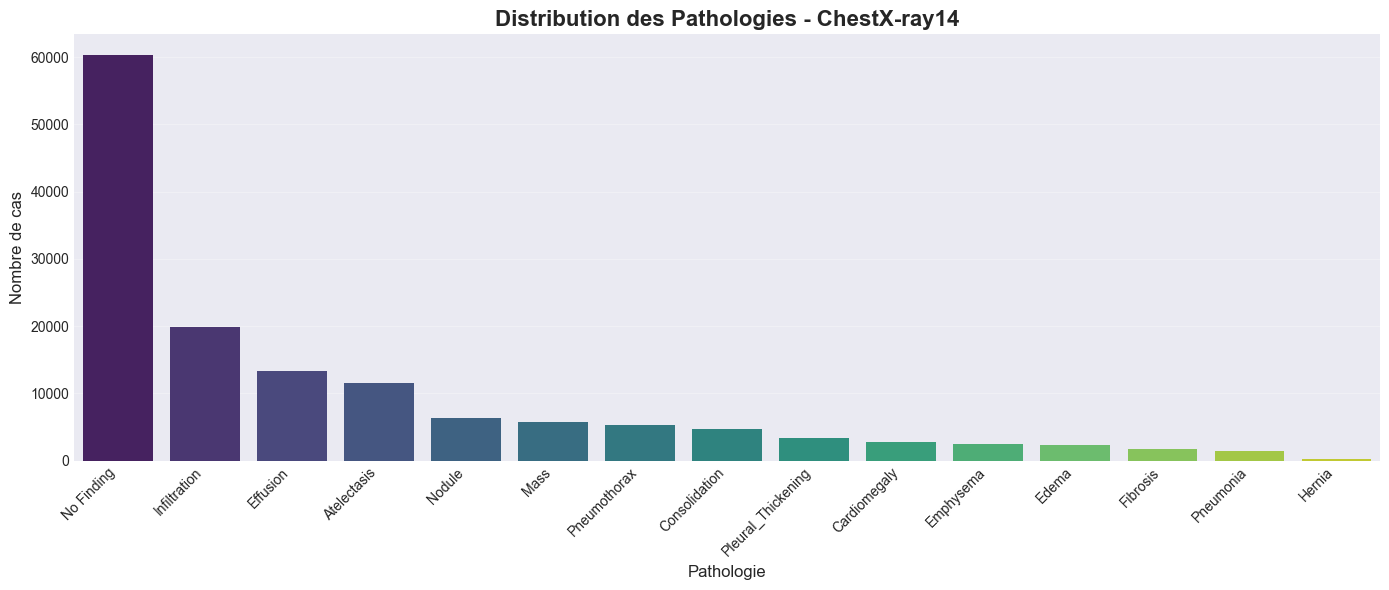


✅ Total d'images : 112,120
✅ Total de pathologies (avec doublons) : 141,537


In [7]:
# Graphique en barres
findings_df = pd.DataFrame(finding_counts.most_common(), 
                          columns=['Pathologie', 'Count'])

plt.figure(figsize=(14, 6))
sns.barplot(data=findings_df, x='Pathologie', y='Count', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.title('Distribution des Pathologies - ChestX-ray14', fontsize=16, fontweight='bold')
plt.xlabel('Pathologie', fontsize=12)
plt.ylabel('Nombre de cas', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✅ Total d'images : {len(df):,}")
print(f"✅ Total de pathologies (avec doublons) : {sum(finding_counts.values()):,}")

## 🖼️ Visualisation d'Exemples d'Images

Affichage de radiographies avec leurs pathologies associées.

In [8]:
# Collecter des images des 3 premiers dossiers
all_images = []
for folder in image_folders[:3]:  # Prendre 3 dossiers
    images = glob.glob(f"{folder}/images/*.png")[:100]  # 100 images par dossier
    all_images.extend(images)

print(f"📸 Images collectées : {len(all_images)}")

# Sélectionner 6 images au hasard
if len(all_images) >= 6:
    sample_images = random.sample(all_images, 6)
    print(f"✅ 6 images sélectionnées pour affichage")
else:
    print("⚠️ Pas assez d'images trouvées")

📸 Images collectées : 300
✅ 6 images sélectionnées pour affichage


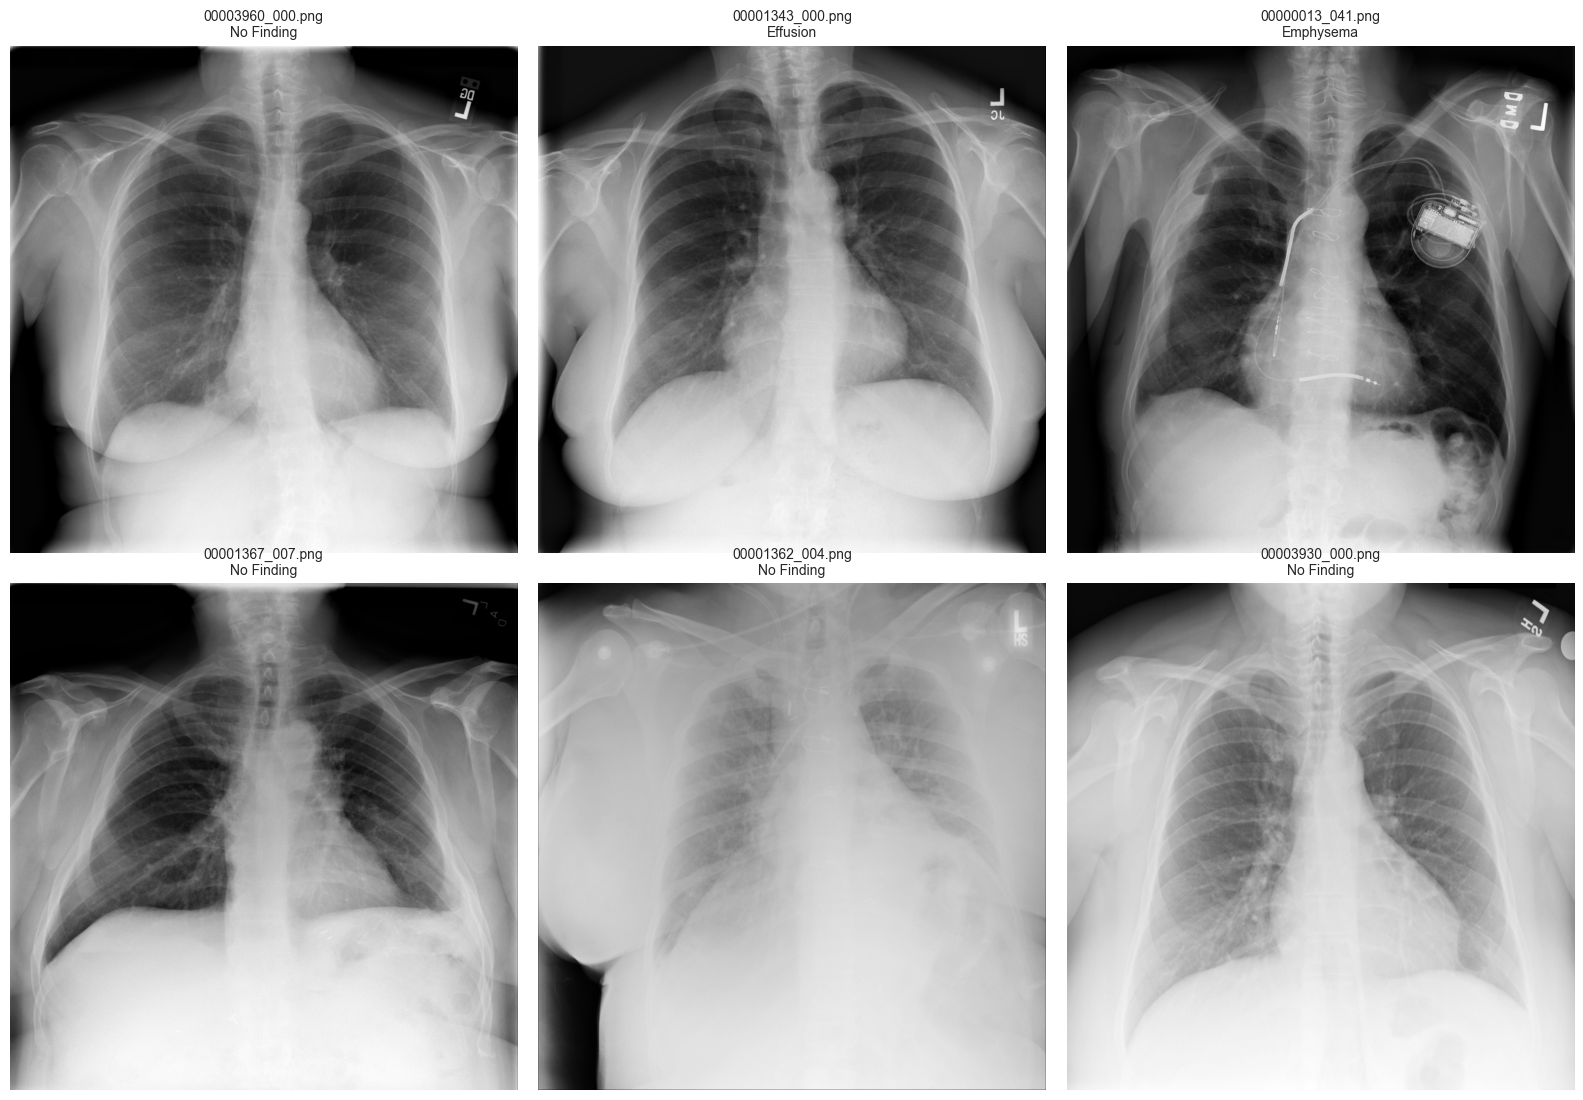


✅ 6 radiographies affichées


In [9]:
# Afficher en grille 2x3
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
axes = axes.ravel()

for idx, img_path in enumerate(sample_images):
    # Charger l'image
    img = Image.open(img_path)
    
    # Extraire le nom du fichier
    img_name = img_path.split('\\')[-1]  # Windows
    
    # Trouver le label dans le CSV
    label_row = df[df['Image Index'] == img_name]
    if not label_row.empty:
        label = label_row['Finding Labels'].values[0]
    else:
        label = "Label non trouvé"
    
    # Afficher
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f"{img_name}\n{label}", fontsize=10)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

print(f"\n✅ {len(sample_images)} radiographies affichées")

## 📏 Statistiques sur les Images

In [10]:
# Analyser les dimensions de 20 images
sample_for_stats = random.sample(all_images, min(20, len(all_images)))

widths = []
heights = []

print("📏 Analyse des dimensions (échantillon de 20 images)...\n")

for img_path in sample_for_stats:
    img = Image.open(img_path)
    widths.append(img.width)
    heights.append(img.height)

print(f"Largeur  : min={min(widths)}, max={max(widths)}, moyenne={sum(widths)//len(widths)}")
print(f"Hauteur  : min={min(heights)}, max={max(heights)}, moyenne={sum(heights)//len(heights)}")
print(f"\n💡 La plupart sont 1024×1024 pixels")

📏 Analyse des dimensions (échantillon de 20 images)...

Largeur  : min=1024, max=1024, moyenne=1024
Hauteur  : min=1024, max=1024, moyenne=1024

💡 La plupart sont 1024×1024 pixels


## ✅ Résumé de l'Exploration

### 📊 Statistiques Clés

| Métrique | Valeur |
|----------|--------|
| **Total d'images** | 112,120 |
| **Résolution standard** | 1024×1024 pixels |
| **Pathologies détectées** | 14 + No Finding |
| **Pathologie la plus fréquente** | Infiltration (17.74%) |
| **Images normales (No Finding)** | 60,361 (53.84%) |
| **Pathologie la plus rare** | Hernia (0.20%) |

---

### 🎯 Observations

1. **Dataset déséquilibré** : Plus de 50% sont "No Finding" (normales)
2. **Multi-label** : Une image peut avoir plusieurs pathologies
3. **Qualité variable** : Résolutions différentes, contraste variable
4. **Besoin de preprocessing** : Normalisation, redimensionnement à 224×224

---

### 📝 Prochaines Étapes

1. ✅ **Preprocessing** : Normalisation, augmentation de données
2. ✅ **Train/Val/Test Split** : 80/10/10
3. ✅ **Entraînement** : 5 modèles (DenseNet, ResNet, EfficientNet, VGG, MobileNet)
4. ✅ **MLflow Tracking** : ~20 runs
5. ✅ **Grad-CAM** : Explainability

In [11]:
# Statistiques finales
print("="*60)
print("🎊 EXPLORATION DES DONNÉES TERMINÉE")
print("="*60)
print()
print(f"📊 Images analysées : {total_images:,}")
print(f"📋 Labels chargés : {len(df):,}")
print(f"🏥 Pathologies : {len(finding_counts)} (incluant No Finding)")
print()
print("✅ Prêt pour le preprocessing et l'entraînement !")
print("="*60)

🎊 EXPLORATION DES DONNÉES TERMINÉE

📊 Images analysées : 112,120
📋 Labels chargés : 112,120
🏥 Pathologies : 15 (incluant No Finding)

✅ Prêt pour le preprocessing et l'entraînement !
